LOAD THE CLEANED DATASET

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# parse_dates converts date_added to a real datetime WHILE reading the file.
# CSV format can't store dtype info — date_added reverts to text on every reload.
df = pd.read_csv('../data/cleaned/netflix_cleaned.csv', parse_dates=['date_added'])


# Stale-file guard: the corrected cleaned file has 8,786 rows. 
# If this fails, re-run Task 1 and re-export the cleaned file.

assert len(df) == 8786, f"{len(df)} rows: re-run Task 1 and re-export the cleaned file"
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8786 entries, 0 to 8785
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8786 non-null   str           
 1   type          8786 non-null   str           
 2   title         8786 non-null   str           
 3   director      6199 non-null   str           
 4   country       8499 non-null   str           
 5   date_added    8786 non-null   datetime64[us]
 6   release_year  8786 non-null   int64         
 7   rating        8786 non-null   str           
 8   duration      8786 non-null   str           
 9   listed_in     8786 non-null   str           
dtypes: datetime64[us](1), int64(1), str(8)
memory usage: 686.5 KB


ORGANISE AND CONTENT COUNT BY RELEASE YEAR

In [2]:
# Titles per release year, in chronological order, value_counts() sorts by count; sort_index() re-sorts by year
yearly_count = df['release_year'].value_counts().sort_index() 
print(yearly_count)

release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1030
2018    1144
2019    1029
2020     953
2021     592
Name: count, Length: 74, dtype: int64


In [3]:
# Latest date anything was added in this dataset; explains the 2021 count
print(df['date_added'].max())

2021-09-25 00:00:00


2021 data is partial year: the dataset only includes titles added up to 25th September 2021.

In [4]:
# Years with no titles are missing from value_counts(), so reindex onto every year and fill the gap with 0 (a real zero: "no titles that year").
# Values come from the data instead of being typed in by hand.
full_range = range(df['release_year'].min(), df['release_year'].max() + 1)
yearly_counts_full = yearly_count.reindex(full_range, fill_value=0)
print(yearly_counts_full)

release_year
1925       1
1926       0
1927       0
1928       0
1929       0
        ... 
2017    1030
2018    1144
2019    1029
2020     953
2021     592
Name: count, Length: 97, dtype: int64


In [5]:
# Print every year, 30 years at a time (pandas hides the middle rows of long tables)
chunk_size = 30
range_start = yearly_counts_full.index.min()   # first year in the data (1925)
range_end = yearly_counts_full.index.max()     # last year in the data (2021)

# range(start, stop, step) jumps forward 30 years at a time: 1925, 1955, 1985, 2015
for start in range(range_start, range_end + 1, chunk_size):
    end = min(start + chunk_size - 1, range_end)    # last year of this chunk, never past 2021
    print(f"--- {start} to {end} ---")
    print(yearly_counts_full.loc[start:end].to_string())   # .loc slices by label, inclusive of both ends
    print()                                                # blank line between chunks

--- 1925 to 1954 ---
release_year
1925    1
1926    0
1927    0
1928    0
1929    0
1930    0
1931    0
1932    0
1933    0
1934    0
1935    0
1936    0
1937    0
1938    0
1939    0
1940    0
1941    0
1942    2
1943    3
1944    3
1945    4
1946    2
1947    1
1948    0
1949    0
1950    0
1951    0
1952    0
1953    0
1954    2

--- 1955 to 1984 ---
release_year
1955     3
1956     2
1957     0
1958     3
1959     1
1960     4
1961     1
1962     3
1963     2
1964     2
1965     2
1966     1
1967     5
1968     3
1969     2
1970     2
1971     5
1972     5
1973    10
1974     7
1975     7
1976     9
1977     7
1978     7
1979    11
1980    11
1981    13
1982    17
1983    11
1984    12

--- 1985 to 2014 ---
release_year
1985     10
1986     13
1987      8
1988     18
1989     16
1990     22
1991     17
1992     23
1993     28
1994     22
1995     25
1996     24
1997     38
1998     36
1999     39
2000     37
2001     45
2002     51
2003     59
2004     64
2005     80
2006     96
20

- From 1925-1978, we have single digit content count per year with 1973(10 titles) as exception.
- From 1979-2007, we have double digit content count per year with  1987(8 titles) as exception.
- From 2008-2021, we have 100+ content count per year, with no exception.

In [6]:
# .loc slices by label and includes BOTH ends, so each phase ends right before the next one starts.
phase1 = yearly_counts_full.loc[:1978]       # 1925-1978
phase2 = yearly_counts_full.loc[1979:2007]   # 1979-2007
phase3 = yearly_counts_full.loc[2008:]       # 2008-2021

In [7]:
print("Phase1 years with 10+ titles:", phase1[phase1 >= 10].to_dict())          # expect only 1973
print("Phase2 years with fewer than 10 titles:", phase2[phase2 < 10].to_dict())  # expect only 1987
print("Phase3 years with fewer than 100 titles:", phase3[phase3 < 100].to_dict())  # expect none

Phase1 years with 10+ titles: {1973: 10}
Phase2 years with fewer than 10 titles: {1987: 8}
Phase3 years with fewer than 100 titles: {}


GROWTH AND DECLINE YEAR OVER YEAR

In [8]:
# How much did the count change each year? (Step 3 of the brief)
phases_2_and_3 = yearly_counts_full.loc[1979:]     # from 1979 there are no zero years, so % change is safe
 
trend_table = pd.DataFrame({
    'titles': phases_2_and_3,
    'change': phases_2_and_3.diff(),                                   # this year minus last year
    'pct_change': (phases_2_and_3.pct_change() * 100).round(1),        # change as a % of last year
})
print(trend_table.loc[2008:])

              titles  change  pct_change
release_year                            
2008             135    47.0        53.4
2009             152    17.0        12.6
2010             192    40.0        26.3
2011             185    -7.0        -3.6
2012             236    51.0        27.6
2013             286    50.0        21.2
2014             351    65.0        22.7
2015             555   204.0        58.1
2016             901   346.0        62.3
2017            1030   129.0        14.3
2018            1144   114.0        11.1
2019            1029  -115.0       -10.1
2020             953   -76.0        -7.4
2021             592  -361.0       -37.9


The 2021 row compares a partial year with a full year, so its drop is not a real decline.

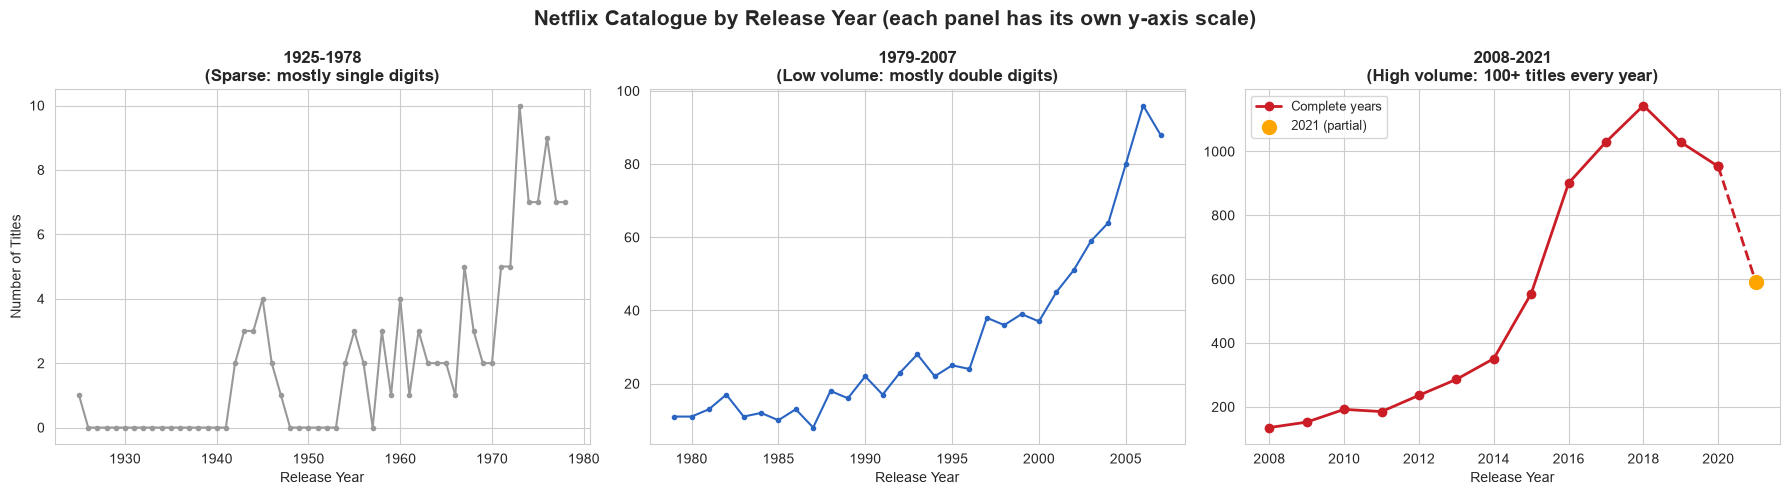

In [9]:
sns.set_style('whitegrid')
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
 
axes[0].plot(phase1.index, phase1.values, marker='o', markersize=3, color='#999999')
axes[0].set_title(f'{phase1.index.min()}-{phase1.index.max()}\n(Sparse: mostly single digits)',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Release Year')
axes[0].set_ylabel('Number of Titles')
 
axes[1].plot(phase2.index, phase2.values, marker='o', markersize=3, color='#2a64c2')
axes[1].set_title(f'{phase2.index.min()}-{phase2.index.max()}\n(Low volume: mostly double digits)',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('Release Year')


# Phase 3: complete years solid, the last step (to the partial year) dashed and highlighted
axes[2].plot(phase3.index[:-1], phase3.values[:-1], marker='o', color='#CB1D26', linewidth=2, label='Complete years')
axes[2].plot(phase3.index[-2:], phase3.values[-2:], marker='o', color='#CB1D26', linewidth=2, linestyle='--')
axes[2].scatter(phase3.index[-1], phase3.values[-1], color='orange', s=100, zorder=5, label='2021 (partial)')
axes[2].set_title(f'{phase3.index.min()}-{phase3.index.max()}\n(High volume: 100+ titles every year)',
                  fontsize=12, fontweight='bold')
axes[2].set_xlabel('Release Year')
axes[2].legend(fontsize=9)
 
fig.suptitle('Netflix Catalogue by Release Year (each panel has its own y-axis scale)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('../screenshots/Task4_01.yearly_release_trend_three_eras.png', dpi=300, bbox_inches='tight')
plt.show()
 



The catalogue falls into three volume bands. Each panel has its own y-axis scale, because one shared scale would flatten the first two bands. 2021 is flagged (orange marker, dashed line) as a partial year: the dataset only includes titles added through 25 September 2021.

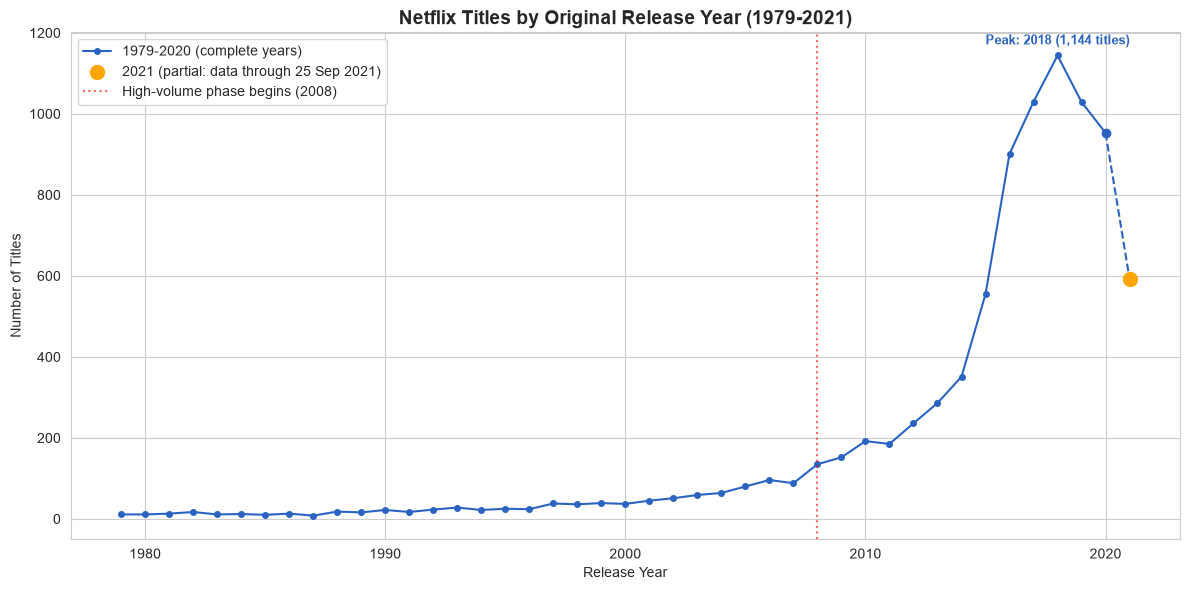

In [10]:
# 1979-2021
phases_2_and_3 = yearly_counts_full.loc[1979:]
first_year = phases_2_and_3.index[0]
last_year = phases_2_and_3.index[-1]
 
fig, ax = plt.subplots(figsize=(12, 6))
 
ax.plot(phases_2_and_3.index[:-1], phases_2_and_3.values[:-1], marker='o', markersize=4,
        color='#2a64c2', linewidth=1.5, label=f'{first_year}-{last_year - 1} (complete years)')
ax.plot(phases_2_and_3.index[-2:], phases_2_and_3.values[-2:], marker='o',
        color='#2a64c2', linewidth=1.5, linestyle='--')
ax.scatter(last_year, phases_2_and_3.values[-1], color='orange', s=100, zorder=5,
           label=f'{last_year} (partial: data through 25 Sep {last_year})')
# Find and label the peak year only
peak_year = phases_2_and_3.idxmax()
peak_count = phases_2_and_3.max()
ax.annotate(f'Peak: {peak_year} ({peak_count:,} titles)', xy=(peak_year, peak_count),
            xytext=(0, 8), textcoords='offset points', ha='center',
            fontsize=9, fontweight='bold', color='#2a64c2')
 
ax.axvline(x=phase3.index[0], color='red', linestyle=':', alpha=0.6,
           label=f'High-volume phase begins ({phase3.index[0]})')
 
ax.set_title(f'Netflix Titles by Original Release Year ({first_year}-{last_year})', fontsize=14, fontweight='bold')
ax.set_xlabel('Release Year')
ax.set_ylabel('Number of Titles')
ax.legend()
 
plt.tight_layout()
plt.savefig('../screenshots/Task4_02.yearly_release_trend_1979_2021.png', dpi=300, bbox_inches='tight')
plt.show()


On one shared scale, counts stay low through the 1990s and 2000s, then climb sharply after 2008 (dotted line), peaking at 1,144 titles in 2018 before falling in 2019 and 2020. 2021 (orange marker, dashed line) is a partial year and cannot be read as a decline.
 

In [11]:
# the numbers the findings below rely on
print(f"Released {phase3.index.min()}-{phase3.index.max()}: {phase3.sum():,} titles "
      f"({phase3.sum() / len(df) * 100:.1f}% of the catalogue)")
print(f"Peak year: {peak_year} with {peak_count:,} titles")
print("Largest rises in titles:")
print(trend_table['change'].nlargest(2))
print("After the peak:", phase3.loc[peak_year + 1:].to_dict())

Released 2008-2021: 7,741 titles (88.1% of the catalogue)
Peak year: 2018 with 1,144 titles
Largest rises in titles:
release_year
2016    346.0
2015    204.0
Name: change, dtype: float64
After the peak: {2019: 1029, 2020: 953, 2021: 592}


FINDINGS, INTERPRETATION AND LIMITATIONS

Findings
- 88.1% of titles (7,741) were released 2008-2021; earlier years are sparse.
- Every year from 2008 has 100 or more titles. The largest rises were 2015 (+204) and 2016 (+346), and the peak is 2018 with 1,144 titles.
- 2019 (1,029) and 2020 (953) are below the peak. 2021 (592) is a partial year (titles added through 25 September 2021), so it cannot be read as a decline.

Interpretation (hypotheses; the dataset cannot prove causes)
- The catalogue is overwhelmingly modern, consistent with a platform that expanded its library mainly after the mid-2010s.
- The 2019-2020 dip could reflect slower production, licensing changes or reporting lag.

Limitations
- release_year is the title's ORIGINAL release year, not the year Netflix produced it; most of the catalogue is licensed content, so this is not a measure of "Netflix production".
- The data is a catalogue snapshot: older titles may have left the platform, so sparse early years show what is available, not how much was made.
- 2021 is incomplete.